
# Mini Project 2: Handwritten Digit Classifier

## Objective
To build a fully connected neural network using PyTorch to classify handwritten digits from 0 to 9 using the MNIST dataset.

## Technologies Used
- Python
- PyTorch
- NumPy
- Matplotlib
- Scikit-learn
- Google Colab


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch Version:", torch.__version__)
print("NumPy Version:", np.__version__)
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")


PyTorch Version: 2.11.0+cpu
NumPy Version: 2.1.3
Device: CPU


## 1. Loading the MNIST Dataset

MNIST is a collection of handwritten digit images.
It contains 60,000 training images and 10,000 testing images.

Each image is a grayscale image of size 28 × 28 pixels.
The labels represent digits from 0 to 9.

In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 61.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.77MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.0MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.05MB/s]

Training samples: 60000
Testing samples: 10000


## 2. Exploring the MNIST Dataset

Display a few sample images from the training dataset along with their actual labels.

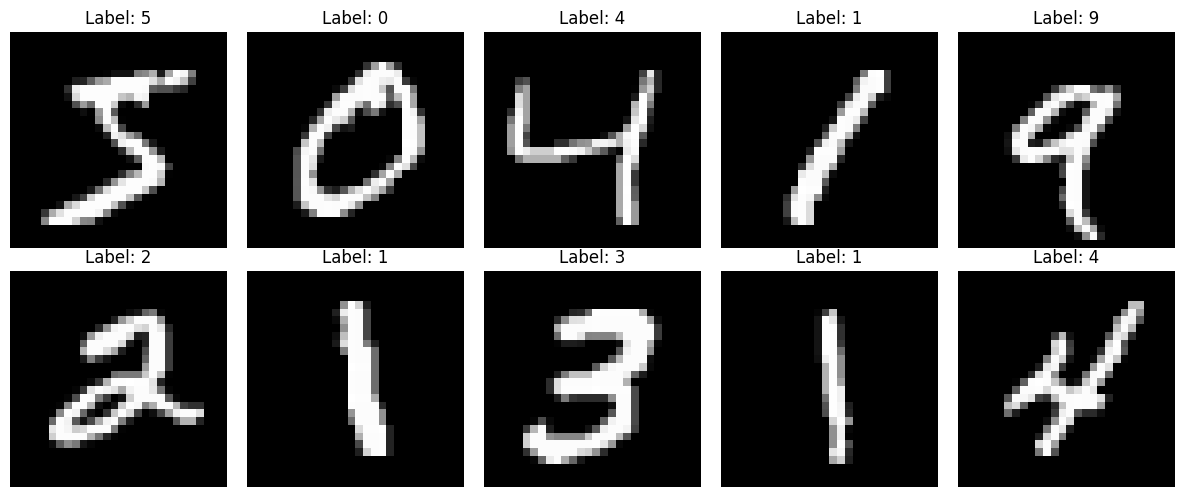

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Data Preprocessing and DataLoaders

Convert images into tensors and organize the training and testing datasets into batches.

Each image contains 28 × 28 pixels.
We use a batch size of 64 for training.

In [4]:
from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel value range:", images.min().item(), "to", images.max().item())

Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Pixel value range: 0.0 to 1.0


## 4. Building the Neural Network

The neural network contains:

1. Input layer: 784 neurons (28 × 28 pixels).
2. Hidden layer 1: 128 neurons with ReLU activation.
3. Hidden layer 2: 64 neurons with ReLU activation.
4. Output layer: 10 neurons representing digits 0 to 9.

The Flatten operation converts each 28 × 28 image into a vector of 784 values.

In [5]:
class DigitClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


model = DigitClassifier()

print(model)

DigitClassifier(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


## 5. Model Configuration

CrossEntropyLoss is used because this is a multi-class classification problem with 10 possible classes.

Adam optimizer updates the model weights to reduce the prediction error.

Learning rate: 0.001

In [6]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss Function:", criterion)
print("Optimizer:", optimizer)

Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 6. Training the Neural Network

Train the model using the MNIST training dataset.

During training:
1. Perform forward propagation.
2. Calculate the loss.
3. Perform backpropagation.
4. Update weights using the Adam optimizer.

Train the model for 5 epochs.

In [7]:
epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    print(f"Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.4f}")

Epoch [1/5], Loss: 0.3503
Epoch [2/5], Loss: 0.1431
Epoch [3/5], Loss: 0.0976
Epoch [4/5], Loss: 0.0746
Epoch [5/5], Loss: 0.0569


## 7. Model Evaluation

Evaluate the trained neural network using the MNIST testing dataset.

Calculate the total number of correct predictions and the overall test accuracy.

In [8]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print("Total Test Images:", total)
print("Correct Predictions:", correct)
print(f"Test Accuracy: {accuracy:.2f}%")

Total Test Images: 10000
Correct Predictions: 9741
Test Accuracy: 97.41%


## 8. Sample Predictions

Display 10 test images with their actual labels and predicted labels.

This helps us understand how the trained model recognises handwritten digits.

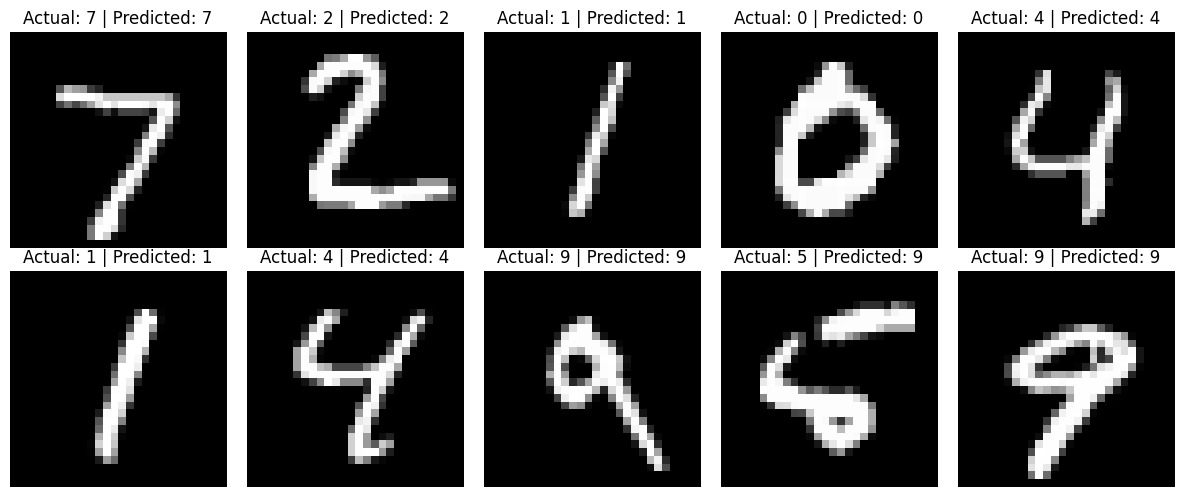

In [9]:
model.eval()

images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = model(images)
    predictions = torch.argmax(outputs, dim=1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")

    actual = labels[i].item()
    predicted = predictions[i].item()

    ax.set_title(f"Actual: {actual} | Predicted: {predicted}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 9. Confusion Matrix

A confusion matrix evaluates the classification performance of the model.

It compares actual digit labels with predicted digit labels for all 10,000 test images.

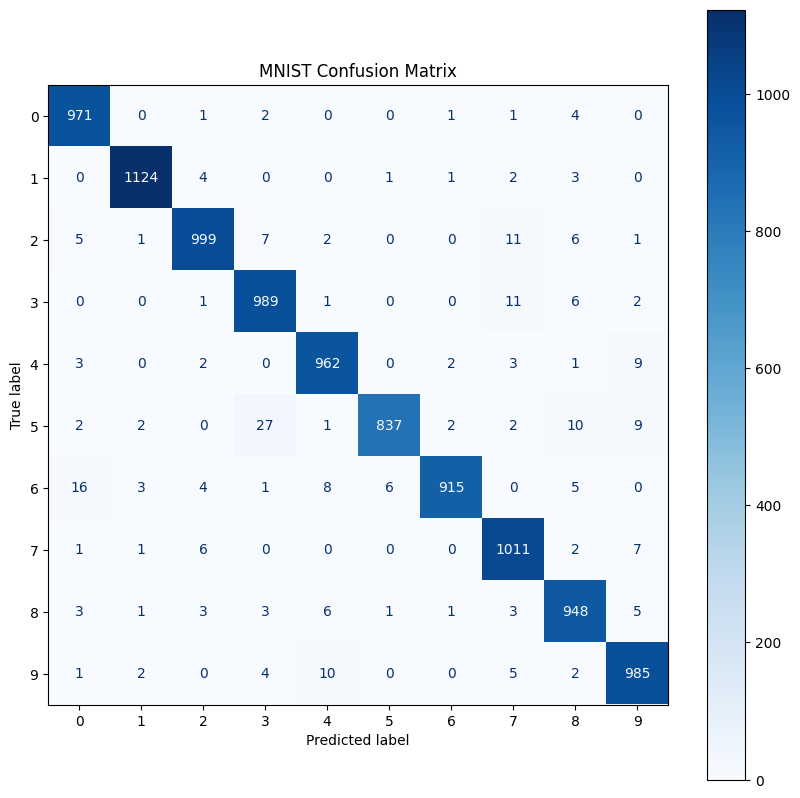

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_predictions)

fig, ax = plt.subplots(figsize=(10, 10))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

display.plot(cmap="Blues", ax=ax)
plt.title("MNIST Confusion Matrix")
plt.show()

## 10. Error Analysis

Identify at least five incorrectly classified images.

Display each image with its actual digit and predicted digit to understand where the model makes mistakes.

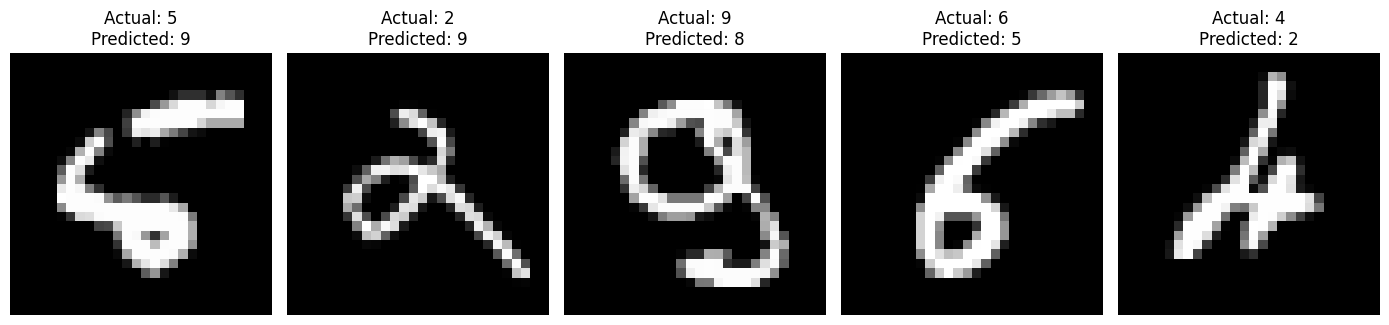

In [12]:
model.eval()

wrong_images = []
wrong_actual = []
wrong_predicted = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        wrong_indices = (predictions != labels).nonzero(as_tuple=True)[0]

        for idx in wrong_indices:
            wrong_images.append(images[idx])
            wrong_actual.append(labels[idx].item())
            wrong_predicted.append(predictions[idx].item())

        if len(wrong_images) >= 5:
            break

fig, axes = plt.subplots(1, 5, figsize=(14, 4))

for i, ax in enumerate(axes):
    ax.imshow(wrong_images[i].squeeze(), cmap="gray")
    ax.set_title(
        f"Actual: {wrong_actual[i]}\nPredicted: {wrong_predicted[i]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

## 11. Error Analysis and Observations

The model achieved 97.41% test accuracy but still made some incorrect predictions.

Five examples of incorrect predictions:

1. Actual 5 predicted as 9.
2. Actual 2 predicted as 9.
3. Actual 9 predicted as 8.
4. Actual 6 predicted as 5.
5. Actual 4 predicted as 2.

### Reasons for Incorrect Predictions

- Some handwritten digits have similar shapes.
- Different writing styles make digit recognition difficult.
- Some images contain unclear or irregular strokes.
- Small image resolution can make certain digits difficult to distinguish.

### Conclusion

The model performs well on most handwritten digits.
However, confusing handwritten patterns can lead to incorrect predictions.

## 12. Project Conclusion

The Handwritten Digit Classifier was successfully developed using PyTorch and the MNIST dataset.

The fully connected neural network contains two hidden layers with ReLU activation functions.

### Final Results

- Training Images: 60,000
- Testing Images: 10,000
- Epochs: 5
- Optimizer: Adam
- Learning Rate: 0.001
- Loss Function: CrossEntropyLoss
- Test Accuracy: 97.41%
- Correct Predictions: 9,741
- Incorrect Predictions: 259

The project demonstrates how deep learning can be used to recognise handwritten digits from 0 to 9.